# Les échecs comme problème de recherche

Un complément à la présentation 16 sur la recherche en largeur

Marcel Turcotte

## Objectifs d’apprentissage

Ce complément d’autoapprentissage applique la terminologie de la
recherche et la recherche en largeur (*breadth-first search*, BFS) de la
présentation 16 à un puzzle soumis à une contrainte. Il utilise les
règles de déplacement des pièces d’échecs sans simuler une partie
complète. BFS fournit un point de comparaison pour étudier des méthodes
de recherche plus avancées dans les présentations suivantes.

À la fin de cet exemple, nous serons capables de :

- formuler un puzzle en termes d’états, d’actions, de transitions, d’une
  contrainte, d’un test d’objectif et d’un coût de chemin ;
- expliquer comment la contrainte de sécurité détermine les actions
  disponibles ;
- expliquer l’importance de la détection des états répétés ;
- utiliser BFS pour trouver une solution comportant le moins de coups
  possible et décrire ce que la recherche a exploré.

## Le puzzle

Ce problème est inspiré d’un exercice de
<a href="https://lichess.org/learn#/9/5" class="external"
data-icon="true">Lichess Learn</a>.

Les Blancs jouent successivement ; les Noirs ne jouent jamais. Les
Blancs doivent capturer toutes les pièces noires en aussi peu de coups
que possible. Après chaque coup des Blancs, toute pièce blanche attaquée
par une pièce noire doit être défendue par une autre pièce blanche.

La position initiale peut enfreindre cette règle de sécurité. Elle est
même délibérément non sûre : le premier coup des Blancs doit corriger le
problème.

### Formulation du problème de recherche

| Composante | Définition dans ce puzzle |
|------------------------------------|------------------------------------|
| **État** | La position et le type de toutes les pièces |
| **État initial** | La position encodée ci-dessous en notation FEN |
| **Actions** | Les coups pseudo-légaux des Blancs dont les états résultants respectent la contrainte de sécurité |
| **Modèle de transition** | Déplacer une pièce blanche ; retirer une pièce noire capturée ; promouvoir un pion qui atteint la dernière rangée |
| **Contrainte de validité** | Toute pièce blanche attaquée est défendue |
| **Test d’objectif** | Il ne reste aucune pièce noire |
| **Coût d’une action** | Une unité par coup des Blancs |

Le **coût du chemin** est le nombre de coups des Blancs. Toutes les
actions ont le même coût ; BFS trouve donc une solution comportant le
moins de coups possible. L’implémentation énumère d’abord les *actions
candidates* selon les règles de déplacement des pièces, puis conserve
uniquement celles dont les états résultants respectent la contrainte de
sécurité.

## Configuration et position initiale

Pour utiliser votre propre environnement de carnets Python, installez
les dépendances une seule fois, puis sélectionnez le noyau de cet
environnement :

``` bash
python -m pip install chess resvg-py ipykernel
```

In [2]:
from collections import deque
from dataclasses import dataclass
from typing import Optional

import chess
import chess.svg
import resvg_py
from IPython.display import Image, Markdown, display

In [3]:
def board_image(
    position,
    *,
    display_size=420,
    scale=2,
    lastmove=None,
    fill=None,
):
    """Retourne un échiquier PNG à haute résolution pour le carnet."""
    svg_options = {
        "board": position,
        "size": display_size * scale,
    }

    if lastmove is not None:
        svg_options["lastmove"] = lastmove
    if fill is not None:
        svg_options["fill"] = fill

    svg = chess.svg.board(**svg_options)
    png = resvg_py.svg_to_bytes(svg_string=svg)

    return Image(data=png, width=display_size)

La notation FEN décrit l’échiquier rangée par rangée, de la rangée 8 à
la rangée 1. Les lettres majuscules représentent les pièces blanches ;
les minuscules, les pièces noires. Le `w` indique que les Blancs jouent
ensuite.

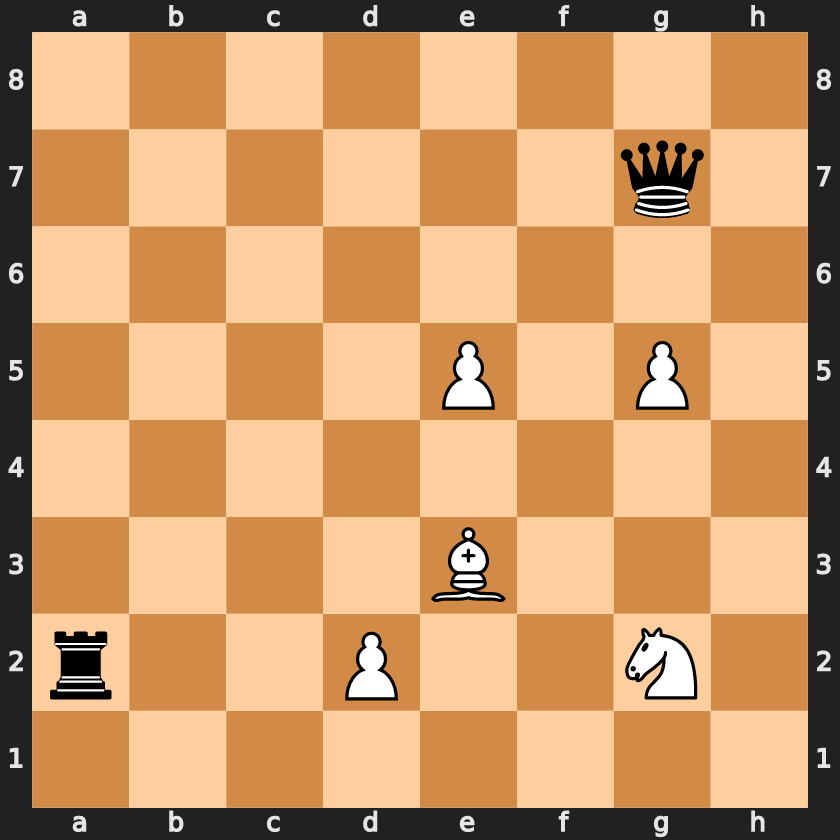

In [4]:
START_FEN = "8/6q1/8/4P1P1/8/4B3/r2P2N1/8 w - - 0 1"

board = chess.Board(START_FEN)
display(board_image(board))

La position contient une tour noire en a2 et une dame noire en g7. Les
Blancs ont des pions en d2, e5 et g5, un fou en e3 et un cavalier en g2.
Les rois sont inutiles dans ce puzzle ; nous utilisons donc des
déplacements *pseudo-légaux* plutôt que les règles de mise en échec. La
promotion habituelle des pions est autorisée ; le roque et la prise en
passant sont absents.

## Test d’objectif

Un état objectif ne contient aucune pièce noire. Exprimer l’objectif
sous forme d’un petit prédicat indépendant facilite sa vérification et
sa réutilisation.

In [5]:
def is_goal(position):
    """Retourne True exactement lorsqu'il ne reste aucune pièce noire."""
    return not any(
        piece.color == chess.BLACK
        for piece in position.piece_map().values()
    )


assert not is_goal(board)

## La contrainte de sécurité

Soit $T(p,s)$ le fait qu’une pièce noire attaque la pièce blanche $p$
dans l’état $s$, et $D(p,s)$ le fait qu’une autre pièce blanche la
défend. Un état valide après un coup satisfait

$$
\forall p \in W(s), \qquad T(p,s) \Rightarrow D(p,s).
$$

Une pièce blanche qui n’est pas attaquée n’a pas besoin d’être défendue.
La sécurité est une propriété de la *position résultante entière*, et
pas seulement de la pièce qui vient de bouger.

In [6]:
def threatened_white_squares(position):
    """Retourne les cases des pièces blanches attaquées par les Noirs."""
    return {
        square
        for square, piece in position.piece_map().items()
        if piece.color == chess.WHITE
        and position.attackers(chess.BLACK, square)
    }


def undefended_white_squares(position):
    """Retourne les cases des pièces blanches attaquées et non défendues."""
    return {
        square
        for square in threatened_white_squares(position)
        if not position.attackers(chess.WHITE, square)
    }


def is_safe(position):
    """
    Détermine si une position respecte la règle de sécurité du puzzle.

    Une position est sûre si chaque pièce blanche attaquée par au moins une
    pièce noire est défendue par au moins une autre pièce blanche. Les pièces
    blanches qui ne sont pas attaquées n'ont pas besoin d'être défendues.
    """
    return not undefended_white_squares(position)


initial_problems = sorted(
    chess.square_name(square) for square in undefended_white_squares(board)
)
print("Pièces blanches non sûres dans l'état initial :", initial_problems)
assert not is_safe(board)
assert initial_problems == ["e5"]

Pièces blanches non sûres dans l'état initial : ['e5']

La sortie confirme l’interprétation voulue du puzzle : le pion en e5 est
attaqué par la dame et n’a aucun défenseur.

## Vérifications : coups autorisés et interdits

Avant de lancer la recherche, nous devons vérifier la règle de
transition à l’aide d’exemples dont nous connaissons déjà les réponses.
La fonction ci-dessous applique un coup des Blancs et leur redonne le
trait, puisque les Noirs ne jouent jamais dans ce puzzle.

Les coups utilisent la **notation UCI** : `e5e6` déplace une pièce de e5
à e6. Une lettre finale indique une promotion : `e7e8q` déplace un pion
en e8 et le promeut en dame.

In [7]:
def after(position, uci):
    """Retourne l'état après un coup pseudo-légal des Blancs en notation UCI."""
    parent = position.copy(stack=False)
    parent.turn = chess.WHITE
    move = chess.Move.from_uci(uci)

    if move not in parent.pseudo_legal_moves:
        raise ValueError(f"{uci} n'est pas un coup pseudo-légal des Blancs")

    parent.push(move)
    parent.turn = chess.WHITE
    return parent


expected = {
    "e3f4": True,   # Le fou défend maintenant e5.
    "e5e6": True,   # Le pion se soustrait à l'attaque de la dame.
    "g2h4": False,  # Le problème initial en e5 persiste.
    "d2d3": False,  # La tour attaque maintenant le cavalier non défendu en g2.
}

for uci, should_be_safe in expected.items():
    child = after(board, uci)
    problems = sorted(
        chess.square_name(square)
        for square in undefended_white_squares(child)
    )
    result = is_safe(child)
    print(
        f"{uci}: {'autorisé' if result else 'interdit':9s} "
        f"(non défendues : {problems or 'aucune'})"
    )
    assert result == should_be_safe

e3f4: autorisé  (non défendues : aucune)
e5e6: autorisé  (non défendues : aucune)
g2h4: interdit  (non défendues : ['e5'])
d2d3: interdit  (non défendues : ['e5', 'g2'])

Ces exemples montrent pourquoi la validité doit être vérifiée *après*
l’application d’une action. Par exemple, `g2h4` est un déplacement
normal du cavalier, mais il est interdit parce que l’état résultant
laisse encore e5 attaqué et non défendu.

## Génération des successeurs valides

La génération des successeurs comporte trois étapes conceptuelles :

$$
\begin{aligned}
\text{action candidate}
&\longrightarrow \text{appliquer la transition} \\
&\longrightarrow
\text{conserver l'état seulement s'il est sûr}.
\end{aligned}
$$

In [8]:
def expand(position):
    """Produit `(move, child)` pour chaque état sûr à un coup des Blancs."""
    parent = position.copy(stack=False)
    parent.turn = chess.WHITE

    for move in parent.pseudo_legal_moves:
        child = parent.copy(stack=False)
        child.push(move)
        child.turn = chess.WHITE

        if is_safe(child):
            yield move, child


first_moves = [move.uci() for move, _ in expand(board)]
print(f"L'état initial possède {len(first_moves)} successeurs valides :")
print(first_moves)

assert "e3f4" in first_moves
assert "e5e6" in first_moves
assert "g2h4" not in first_moves
assert "d2d3" not in first_moves

L'état initial possède 2 successeurs valides :
['e3f4', 'e5e6']

## États répétés et clé d’état

Plusieurs chemins peuvent mener au même arrangement. Les pièces peuvent
aussi se déplacer puis revenir à leur position précédente, créant des
cycles. Sans détection des états répétés, BFS perdrait du temps à
redécouvrir ces positions.

Seule la disposition des pièces affecte les décisions futures dans ce
puzzle : les Blancs jouent toujours, il n’y a ni roque ni prise en
passant, et les compteurs de coups n’ont aucune importance.
`board_fen()` fournit donc une clé d’état appropriée sans conserver les
données administratives inutiles de la notation FEN complète.

In [9]:
def state_key(position):
    """Retourne la partie de l'état qui importe pour les décisions futures."""
    return position.board_fen()


assert state_key(board) == START_FEN.split()[0]

Il s’agit d’une leçon générale de modélisation : un état de recherche
doit conserver tout ce qui peut affecter l’avenir, mais pas
nécessairement tout ce qu’une bibliothèque enregistre.

## Recherche en largeur

La frontière conserve les nœuds de recherche sous forme de paires
`(state, path)`. Ici, `path` est une séquence d’**actions** (coups
d’échecs) ; l’implémentation de la présentation 16 enregistre plutôt la
séquence des **états** le long d’un chemin. Les deux décrivent comment
atteindre l’état du nœud depuis l’état initial.

L’ensemble `reached` contient les états de la frontière et les états
déjà développés. Il évite de répéter le travail. Les compteurs révèlent
l’effort de recherche qui serait autrement caché derrière la réponse
finale.

In [10]:
@dataclass(frozen=True)
class SearchStats:
    solution_depth: Optional[int]
    states_expanded: int
    states_generated: int
    duplicate_states: int
    max_frontier_size: int
    reached_states: int


def bfs(start):
    """Trouve une solution avec le moins de coups par BFS sur graphe."""
    root = start.copy(stack=False)
    root.turn = chess.WHITE

    frontier = deque([(root, [])])
    reached = {state_key(root)}

    expanded = 0
    generated = 0
    duplicates = 0
    max_frontier = len(frontier)

    while frontier:
        position, path = frontier.popleft()

        # BFS teste les états par longueur de chemin non décroissante.
        if is_goal(position):
            stats = SearchStats(
                solution_depth=len(path),
                states_expanded=expanded,
                states_generated=generated,
                duplicate_states=duplicates,
                max_frontier_size=max_frontier,
                reached_states=len(reached),
            )
            return path, stats

        expanded += 1

        for move, child in expand(position):
            generated += 1
            key = state_key(child)

            if key in reached:
                duplicates += 1
                continue

            reached.add(key)
            frontier.append((child, path + [move]))
            max_frontier = max(max_frontier, len(frontier))

    stats = SearchStats(
        solution_depth=None,
        states_expanded=expanded,
        states_generated=generated,
        duplicate_states=duplicates,
        max_frontier_size=max_frontier,
        reached_states=len(reached),
    )
    return None, stats

Le code effectue une **recherche sur graphe** (*graph search*) :
`reached` garantit que chaque disposition distincte des pièces entre
dans la frontière au plus une fois. Ici, « générés » compte les
successeurs valides avant le retrait des doublons, tandis que «
développés » compte les états non objectifs retirés de la frontière et
examinés.

## Exécuter et examiner la recherche

In [11]:
solution, stats = bfs(board)

if solution is None:
    print("Aucune solution trouvée.")
else:
    print(f"Longueur minimale de la solution : {len(solution)} coups")
    print("Coups :", " ".join(move.uci() for move in solution))

print()
print(f"États développés :              {stats.states_expanded:,}")
print(f"États générés :                 {stats.states_generated:,}")
print(f"États répétés :                 {stats.duplicate_states:,}")
print(f"Taille maximale de la frontière : {stats.max_frontier_size:,}")
print(f"États distincts atteints :      {stats.reached_states:,}")

assert solution is not None
assert len(solution) == stats.solution_depth

Longueur minimale de la solution : 8 coups
Coups : e5e6 g2h4 h4f5 f5g7 e6e7 e7e8q e8g8 g8a2

États développés :              4,101
États générés :                 50,202
États répétés :                 34,959
Taille maximale de la frontière : 11,143
États distincts atteints :      15,244

La solution est la plus courte parce que chaque arête coûte un coup et
que BFS examine les états moins profonds avant les états plus profonds.
Les statistiques montrent aussi que la file n’est qu’une partie de
l’algorithme : la représentation des états, le filtrage selon la
contrainte et la détection des doublons influencent tous la recherche de
façon importante.

## Visualiser la solution

L’affichage ci-dessous commence par l’état initial, puis montre chaque
coup de la solution minimale. Le dernier coup est mis en évidence par
`lastmove`. Les cases dorées indiquent les pièces blanches actuellement
attaquées par les Noirs ; puisque tous les états après un coup sont
valides, chacune de ces pièces a aussi un défenseur blanc.

In [12]:
THREATENED_COLOR = "#f2c14e99"


def display_solution(start, moves, size=380):
    """Affiche l'état initial et chaque position annotée d'un chemin."""
    current = start.copy(stack=False)
    current.turn = chess.WHITE

    display(Markdown("### Position initiale"))
    display(board_image(current, display_size=size))

    for number, move in enumerate(moves, start=1):
        assert move in current.pseudo_legal_moves
        current.push(move)
        current.turn = chess.WHITE

        threatened = threatened_white_squares(current)
        names = sorted(chess.square_name(square) for square in threatened)
        annotation = ", ".join(names) if names else "aucune"
        fill = {square: THREATENED_COLOR for square in threatened}

        display(
            Markdown(
                f"\n### Coup {number} : `{move.uci()}`\n\n"
                f"Pièces blanches attaquées et défendues : {annotation}.\n"
            )
        )
        display(
            board_image(
                current,
                display_size=size,
                lastmove=move,
                fill=fill,
            )
        )

        # Chaque état affiché après un coup doit respecter la contrainte.
        assert is_safe(current)

    assert is_goal(current)


display_solution(board, solution)

## Questions de réflexion

1.  Que se passerait-il sans `reached` si un cavalier passait d’une case
    à une autre, puis revenait à sa case initiale ?
2.  Pourquoi BFS minimise-t-il le nombre de coups dans ce puzzle ?

### Prolongements pour les présentations suivantes

- **Présentation 17 — Recherche informée :** Comment l’algorithme
  changerait-il si les coups avaient des coûts différents ? Quelles
  informations sur l’échiquier pourraient fournir une heuristique utile
  pour la recherche gloutonne (*greedy best-first search*) ou A\* ?
- **Présentation 21 — Recherche adversariale :** Comment le problème
  changerait-il si les Noirs pouvaient choisir une réponse ?

La dernière question fait le lien entre la recherche à un seul agent et
la recherche adversariale : dès que les Noirs choisissent aussi leurs
coups, les modèles suivants sont naturellement minimax et l’élagage
alpha-bêta plutôt que BFS dans un environnement passif.